In [1]:
import numpy as np, math
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

import matplotlib.pyplot as plt
from scipy.optimize import brentq

In [2]:
# Constants
G=6.674e-11 
mE=5.972e24
mM=7.348e22
d=3.844e8

In [3]:
# System paramters and basic motion


w =math.sqrt(G*(mE+mM)/d**3) # angular velocity of the system
T = 2*math.pi/w # period of the system

rE= mM*d/(mE+mM) # distance of earth from barycentre
rM= mE*d/(mE+mM) # distance of moon from barycentre
dr_approx = d*(mM/(3*mE))**(1/3) 

# exact L2 distance from the Moon (force balance for a co-rotating rocket)
def balance(dr):
    r = rM + dr
    return -G*mE/(r+rE)**2 - G*mM/dr**2 + w**2*r
dr_exact = brentq(balance, 3e7, 1e8, xtol=1e-3)

def body_pos(t): 
    cos_comp ,sine_comp = np.cos(w*t), np.sin(w*t)
    posE = np.array([-rE*cos_comp, -rE*sine_comp])
    posM = np.array([rM*cos_comp, rM*sine_comp])
    return posE, posM

def body_vel(t):                                           #call using 

    cos_comp, sin_comp = np.cos(w*t), np.sin(w*t)

    velE = np.array([rE*w*sin_comp, -rE*w*cos_comp])
    velM = np.array([-rM*w*sin_comp, rM*w*cos_comp])

    return velE, velM

def initial_conditions_planets(t0):             # call using (posE, posM), (velE, velM) = initial_conditions_planets(t0)

    posE, posM = body_pos(t0)
    velE, velM = body_vel(t0)

    return (posE, posM), (velE, velM)

def init(dr, t):                                                  # call using posS, velS = init(dr, t0)

    cos_comp, sin_comp = np.cos(w*t), np.sin(w*t)

    pos = np.array([(rM+dr)*cos_comp,(rM+dr)*sin_comp])
    vel = np.array([-w*(rM+dr)*sin_comp,w*(rM+dr)*cos_comp])

    return pos, vel

def func_to_solve(t, s):

    pos = s[:2]
    vel = s[2:]
    posE, posM = body_pos(t)
    dE = pos - posE
    dM = pos - posM
    dE3 = np.linalg.norm(dE)**3
    dM3 = np.linalg.norm(dM)**3
    acc = -G*mE*dE/dE3 - G*mM*dM/dM3

    return np.concatenate((vel, acc))


In [4]:
#Scipy Solver 
def Scipy_solver(func,t_span, s, t_eval):
    posS, velS = init(dr, T0)
    s = np.concatenate((posS, velS))
    sol = solve_ivp(func, t_span, s , t_eval=t_eval, method='DOP853', rtol=1e-9, atol=1e-9)
    return sol 

#Scipy Solver with dense output - use this one as you can interpolate better
def Scipy_solver_dense(func, T0, T, n, dr):
    pos,vel = init(dr, T0)
    s=np.concatenate((pos,vel))
    t = np.linspace(T0, T, n)
    sol = solve_ivp(func, [T0, T], s,t_eval=t,method='DOP853',rtol=1e-9,atol=1e-9,dense_output=True)
    positions = sol.y[:2].T
    velocities = sol.y[2:].T
    times = sol.t

    return positions, velocities, times 


In [5]:
#Taylor Solver - add jerk 
def Taylor_solver(dr , T0, T,h=10.0 , store = 200):
    
    N=int(round((T-T0)/h))
    h=(T-T0)/N

    pos ,vel = init(dr,T0)    
    out_pos = []
    out_vel = []
    times = []

    for i in  range(N+1):
        t=T0+i*h
        
        
        if i % store ==0 or i == N:
            out_pos.append(pos)
            out_vel.append(vel)
            times.append(t)

        if i == N:
            break
        
        deriv=func_to_solve(t, np.concatenate((pos,vel)))
        acc = deriv[2:]
        new_pos = pos + h*vel + 0.5*h**2*acc
        new_vel = vel + h*acc

        pos, vel = new_pos, new_vel

    return np.array(out_pos), np.array(out_vel), np.array(times)


In [6]:
def rk_step(f,t,u,h):
    k1 = f(t,u)
    k2 = f(t + h/2, u + h*k1/2)
    k3 = f(t + h/2, u + h*k2/2) 
    k4 = f(t + h, u + h*k3)
    return u + h*(k1 + 2*k2 + 2*k3 + k4)/6

def Runge_Kutta_solver(f, T0, dr, T_end, h):

    pos, vel = init(dr, T0)
    s = np.concatenate((pos, vel))

    states = [s.copy()]
    times = [T0]

    t = T0

    while t < T_end:
        dt = min(h, T_end - t)

        s = rk_step(f, t, s, h)

        t += dt
        states.append(s.copy())
        times.append(t)
    states = np.array(states)
    positions = states[:, :2]
    velocities = states[:, 2:]
    times = np.array(times)

    return positions, velocities, times

In [11]:
# Simulation parameters
T0 = 0
T_end = 3*T
dr = dr_exact
h = 10.0
store = 200
n = 3000

# Initial conditions
pos0, vel0 = init(dr, T0)
s0 = np.concatenate((pos0, vel0))

# Time points for SciPy
times = np.linspace(T0, T, n)

# Taylor solver
pos_T, vel_T, time_T = Taylor_solver(
    dr, T0, T_end, h, store
)

# Runge-Kutta solver
pos_RK, vel_RK, time_RK = Runge_Kutta_solver(
    func_to_solve, T0, dr, T_end, h
)

# SciPy solver
pos_S, vel_S, time_S= Scipy_solver_dense(
    func_to_solve, T0, T_end, n, dr
)

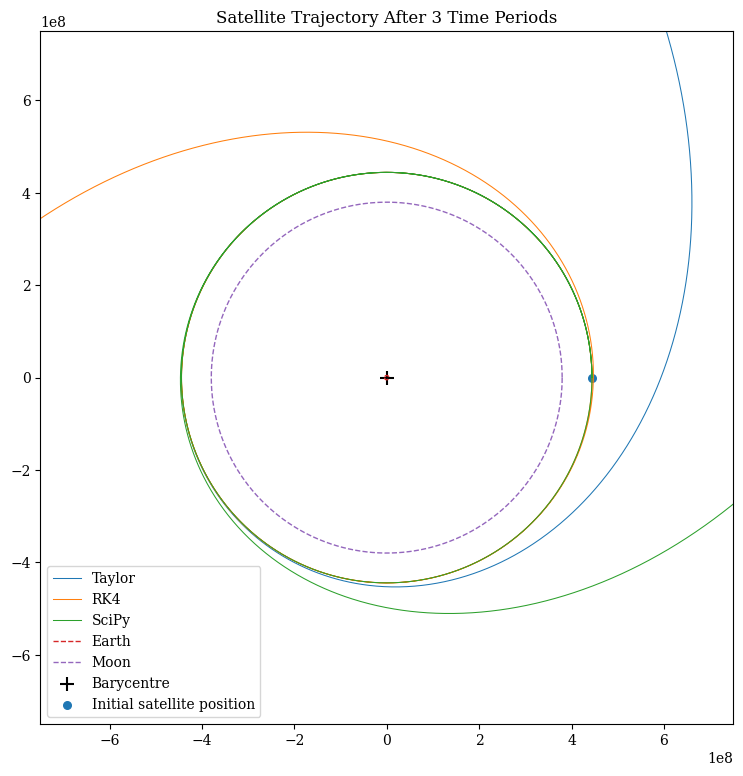

In [12]:


fig, ax = plt.subplots(figsize=(9, 9))
plt.rcParams["font.family"] = "serif"
ax.plot(pos_T[:, 0], pos_T[:, 1], label="Taylor", linestyle= "-", linewidth =  0.75)
ax.plot(pos_RK[:, 0], pos_RK[:, 1], label="RK4", linestyle= "-", linewidth = 0.75)
ax.plot(pos_S[:, 0], pos_S[:, 1], label="SciPy", linestyle= "-", linewidth =  0.75)

earth_positions = []
moon_positions = []
time_bodies= np.linspace(0,T,2000)
for t in time_bodies:
    earth_pos, moon_pos = body_pos(t)
    earth_positions.append(earth_pos)
    moon_positions.append(moon_pos)

earth_positions = np.array(earth_positions)
moon_positions = np.array(moon_positions)

ax.plot(earth_positions[:, 0], earth_positions[:, 1], label="Earth", linestyle= "--", linewidth = 1)
ax.plot(moon_positions[:, 0], moon_positions[:, 1], label="Moon", linestyle= "--", linewidth = 1)

ax.scatter(0, 0, marker="+", color="black", s=100, label="Barycentre")
ax.scatter(pos0[0], pos0[1], marker="o", s=30, label="Initial satellite position")

ax.set_xlim(-0.75e9, 0.75e9)
ax.set_ylim(-0.75e9, 0.75e9)

#ax.set_xlabel("x (m)")
#ax.set_ylabel("y (m)")
ax.set_title("Satellite Trajectory After 3 Time Periods")

ax.set_aspect("equal", adjustable="box")
#ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

In [13]:

T_end=T*3
pos0, vel0 = init(dr, T0)
s0 = np.concatenate((pos0, vel0))

times = np.linspace(T0, T_end, n)

# Taylor solver
pos_T, vel_T, time_T = Taylor_solver(dr, T0, T_end, h, store)

# Runge-Kutta solver
pos_RK, vel_RK, time_RK = Runge_Kutta_solver(func_to_solve, T0, dr, T_end, h)

# SciPy solver
pos_S, vel_S, time_S = Scipy_solver_dense(func_to_solve, T0, T_end, n,dr )

earth_positions = []
moon_positions = []
time_bodies= np.linspace(0,T,2000)
for t in time_bodies:
    earth_pos, moon_pos = body_pos(t)
    earth_positions.append(earth_pos)
    moon_positions.append(moon_pos)

earth_positions = np.array(earth_positions)
moon_positions = np.array(moon_positions)

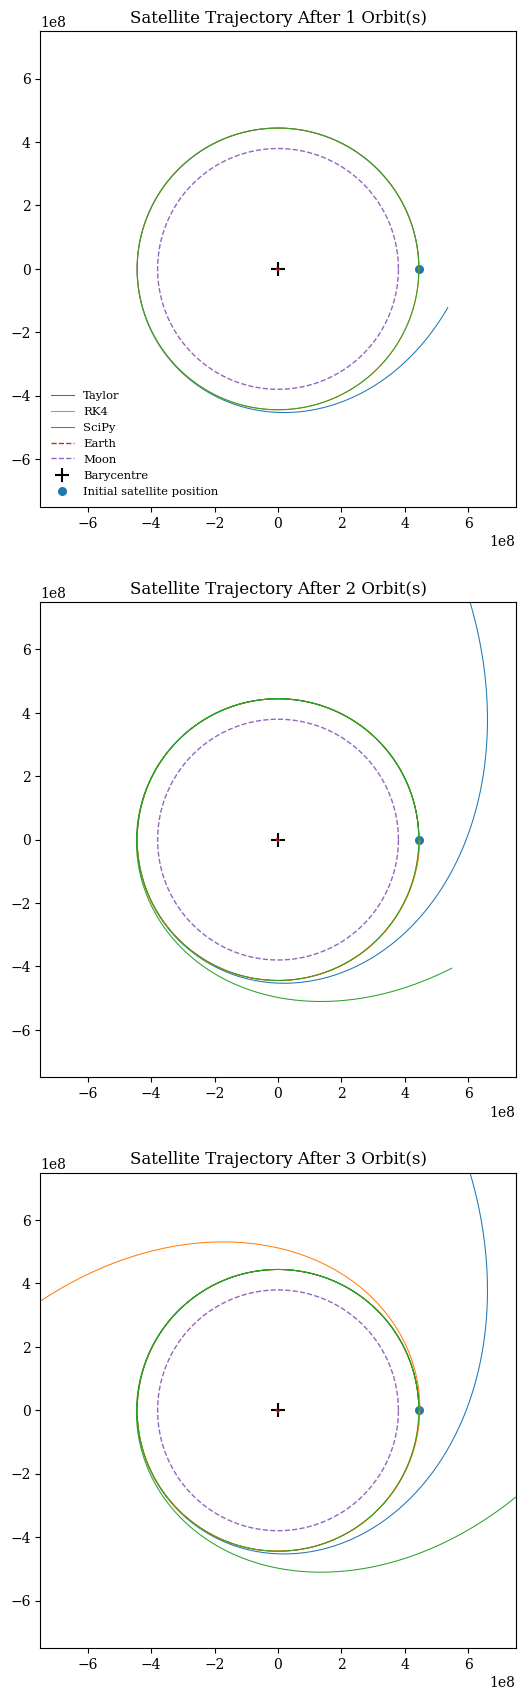

In [17]:
fig, axes = plt.subplots(3,1,figsize=(7, 21))        

for i in range(1,4):
    T_plot = i * T
    mask_T = time_T <= T_plot
    mask_T = time_T <= T_plot
    mask_RK = time_RK <= T_plot
    mask_S = time_S <= T_plot


    ax = axes[i-1]

    ax.plot(pos_T[mask_T, 0], pos_T[mask_T, 1], label="Taylor", linestyle= "-", linewidth =  0.75)
    ax.plot(pos_RK[mask_RK, 0], pos_RK[mask_RK, 1], label="RK4", linestyle= "-", linewidth = 0.75)
    ax.plot(pos_S[mask_S, 0], pos_S[mask_S, 1], label="SciPy", linestyle= "-", linewidth =  0.75)

    earth_positions = []
    moon_positions = []
    time_bodies= np.linspace(0,T,2000)
    for t in time_bodies:
        earth_pos, moon_pos = body_pos(t)
        earth_positions.append(earth_pos)
        moon_positions.append(moon_pos)

    earth_positions = np.array(earth_positions)
    moon_positions = np.array(moon_positions)

    ax.plot(earth_positions[:, 0], earth_positions[:, 1], label="Earth", linestyle= "--", linewidth = 1)
    ax.plot(moon_positions[:, 0], moon_positions[:, 1], label="Moon", linestyle= "--", linewidth = 1)

    ax.scatter(0, 0, marker="+", color="black", s=100, label="Barycentre")
    ax.scatter(pos0[0], pos0[1], marker="o", s=30, label="Initial satellite position")

    ax.set_xlim(-0.75e9, 0.75e9)
    ax.set_ylim(-0.75e9, 0.75e9)

    #ax.set_xlabel("x (m)")
    #ax.set_ylabel("y (m)")
    ax.set_title(f"Satellite Trajectory After {i} Orbit(s)")

    ax.set_aspect("equal", adjustable="box")
    #ax.grid(True, alpha=0.3)
    if i == 1:   
        ax.legend(loc="lower left", fontsize="small", fancybox=False, shadow=False, frameon=False)


plt.tight_layout
plt.savefig('Orbtis over sveral periods')
plt.show()

In [ ]:
#metrics to test how accurate it is 

# graph of sepation over time 
# define a dgegree of inacfcuracy
#stable vs unstable orbits?
# why is the runga kutta better than the sci py one? is it it will diverge eventaully

# change paramters and see how this affects the accuracy 

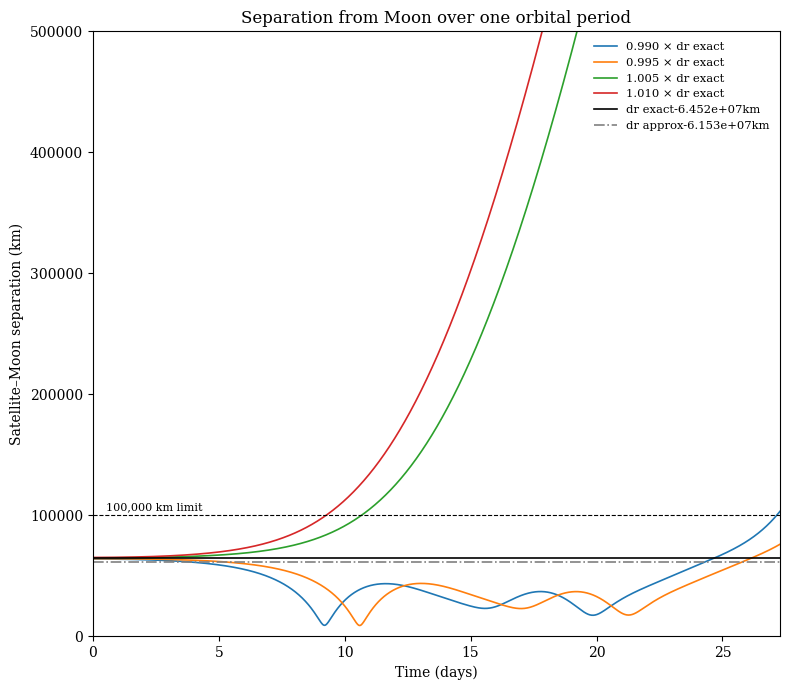

In [51]:
T0 = 0.0
scales = [0.990, 0.995, 1.005, 1.010]
n = 2000

fig, ax = plt.subplots(figsize=(8, 7))
plt.rcParams["font.family"] = "serif"

# the 5 scaled launches
for k in scales:
    pos, vel, t = Scipy_solver_dense(func_to_solve, T0, T, n, k * dr_exact)
    _, posM = body_pos(t)                        # moon position, shape (2, n)
    sep = np.linalg.norm(pos - posM.T, axis=1)   # satellite-Moon separation (m)
    ax.plot(t / 86400, sep / 1e3, linewidth=1.2, label=f"{k:.3f} × dr exact")

# straight lines at dr exact and dr approx
ax.axhline(dr_exact / 1e3, color="black", linestyle="-",  linewidth=1.2, label=f"dr exact-{dr_exact:.4}km")
ax.axhline(dr_approx / 1e3, color="grey",  linestyle="-.", linewidth=1.2, label=f"dr approx-{dr_approx:.4}km")

# 100,000 km reference
ax.axhline(100000, c="k", ls="--", lw=.8) 
ax.text(0.5, 104000, "100,000 km limit", fontsize=8)

#ax.set_yscale("log")          # remove this line if you prefer a linear axis
ax.set_xlabel("Time (days)")
ax.set_ylabel("Satellite–Moon separation (km)")
ax.set_title("Separation from Moon over one orbital period")
ax.set_ylim(0,500000)
ax.set_xlim(0, T / 86400)
ax.legend(fontsize="small", frameon=False)
plt.tight_layout()
plt.show()

Initial dr_exact: 64,522.266 km

Method      Final sep (km)     Difference (km)    Difference (%)
Taylor         197,755.745         133,233.478         206.49225
RK4             64,522.267               0.001           0.00000
SciPy           64,524.990               2.723           0.00422


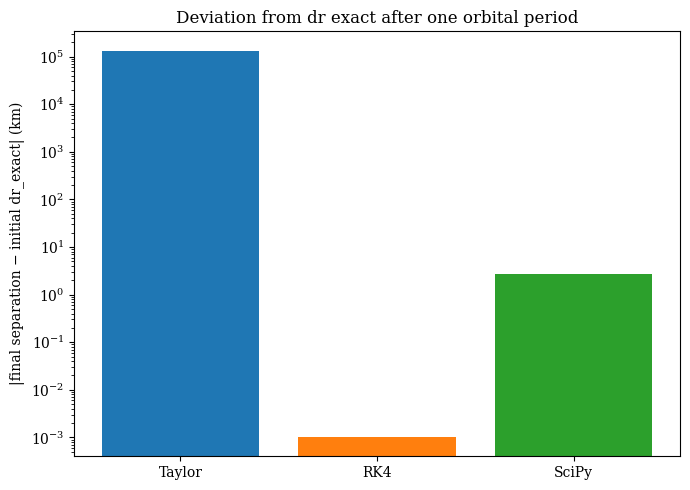

In [49]:
T0 = 0.0
h = 10.0          # step size (s) for Taylor and RK4
n = 2000          # output points for SciPy
dr0 = dr_exact    # launch at the exact L2 distance

def final_separation(pos, t):
    """Satellite-Moon distance (m) at the last time point."""
    _, posM = body_pos(t[-1])
    return np.linalg.norm(pos[-1] - posM)

results = {}

pos, vel, t = Taylor_solver(dr0, T0, T, h, store=200)
results["Taylor"] = final_separation(pos, t)

pos, vel, t = Runge_Kutta_solver(func_to_solve, T0, dr0, T, h)
results["RK4"] = final_separation(pos, t)

pos, vel, t = Scipy_solver_dense(func_to_solve, T0, T, n, dr0)
results["SciPy"] = final_separation(pos, t)

# table
print(f"Initial dr_exact: {dr0/1e3:,.3f} km\n")
print(f"{'Method':<8}{'Final sep (km)':>18}{'Difference (km)':>20}{'Difference (%)':>18}")
for name, sep in results.items():
    diff = sep - dr0
    print(f"{name:<8}{sep/1e3:>18,.3f}{diff/1e3:>20,.3f}{100*diff/dr0:>18.5f}")

# bar chart of absolute error (log scale since the errors differ by orders of magnitude)
names = list(results.keys())
errors = [abs(results[m] - dr0) / 1e3 for m in names]

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(names, errors, color=["tab:blue", "tab:orange", "tab:green"])
ax.set_yscale("log")
ax.set_ylabel("|final separation − initial dr_exact| (km)")
ax.set_title("Deviation from dr exact after one orbital period")
plt.tight_layout()
plt.show()